# SC5002 Lab Assignment 2
## Name: Tan Zi Heng | Matric Number: U2540801B
### AI Acknowlegement: Generative AI tools, including ChatGPT and Claude, were used to assist with coding, debugging, and refining the written report for this assignment.

# Imports & Global Settings

In [ ]:
# ---------- Imports & global settings ----------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans                    # K-Means clustering
from sklearn.preprocessing import StandardScaler      # z-score normalisation

COLORS = ["tab:blue", "tab:red", "tab:green", "tab:orange", "tab:purple"]

# Exercise 1: K-Means customer segmentation

In [ ]:
# ---------- Step 1: Create the dataset (20 customers) ----------
df = pd.DataFrame({
    "Customer": [f"C{i}" for i in range(1, 21)],
    "Income":   list(range(15, 35)),                             # Annual income (k$): 15..34
    "Score":    [39,81,6,77,40,76,6,94,15,73,88,17,40,55,82,20,79,35,83,30],  # Spending score
})

# ---------- Step 2: Normalise features ----------
# K-Means uses Euclidean distance, so a feature with a larger range would dominate.
# StandardScaler rescales each feature to mean 0 and standard deviation 1.
# fit(X): This calculates the mean and standard deviation for each feature in your data (X).
# transform(X): This then scales each feature in X by subtracting its mean and dividing by its standard deviation.
X = df[["Income", "Score"]].values                    # original values (used for plotting)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)                    # scaled values (used for clustering)

## Task 1: K-Means with k=3 and k=5

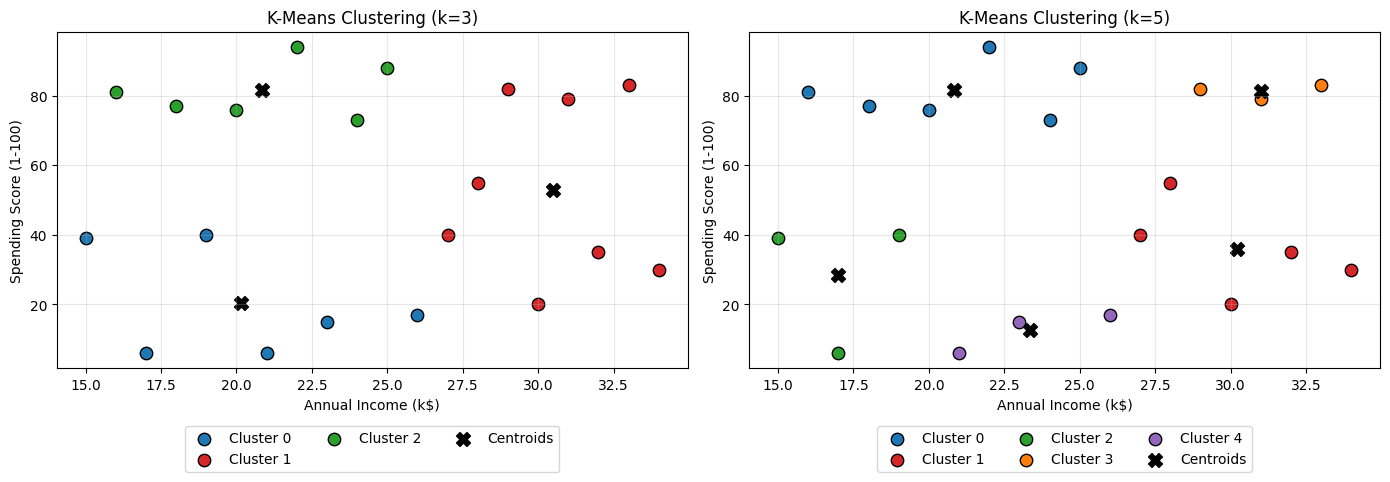

Customer Cluster Assignments:
Customer  Income  Score  Cluster_3  Cluster_5
      C1      15     39          0          2
      C2      16     81          2          0
      C3      17      6          0          2
      C4      18     77          2          0
      C5      19     40          0          2
      C6      20     76          2          0
      C7      21      6          0          4
      C8      22     94          2          0
      C9      23     15          0          4
     C10      24     73          2          0
     C11      25     88          2          0
     C12      26     17          0          4
     C13      27     40          1          1
     C14      28     55          1          1
     C15      29     82          1          3
     C16      30     20          1          1
     C17      31     79          1          3
     C18      32     35          1          1
     C19      33     83          1          3
     C20      34     30          1          1

K-M

In [ ]:
# random_state=42: This sets a seed for the random number generator.
# This is useful for reproducibility; if you run the code again with the same random_state, you'll get the exact same clustering results.

# n_init=50: This parameter specifies the number of times the K-Means algorithm will be run with different centroid seeds.
# The final model will be the one with the lowest Within-Cluster Sum of Squared (WCSS) across all these runs.
# Running with multiple initializations helps to avoid getting stuck in local optima.

# Run K-Means for k=3 and k=5
kmeans3 = KMeans(n_clusters=3, random_state=42, n_init=50)
kmeans5 = KMeans(n_clusters=5, random_state=42, n_init=50)

df["Cluster_3"] = kmeans3.fit_predict(X_scaled)
df["Cluster_5"] = kmeans5.fit_predict(X_scaled)

# Visualize the clusters
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, col, k in zip(
    axes,
    [kmeans3, kmeans5],
    ["Cluster_3", "Cluster_5"],
    [3, 5]
):
    # Plot each cluster with its assigned colour
    for i in range(k):
        cluster = df[df[col] == i]

        ax.scatter(
            cluster["Income"],
            cluster["Score"],
            color=COLORS[i],
            label=f"Cluster {i}",
            s=80,
            edgecolors="black"
        )

    # Convert centroids back to the original scale
    centers = scaler.inverse_transform(model.cluster_centers_)

    ax.scatter(
        centers[:, 0],
        centers[:, 1],
        color="black",
        marker="X",
        s=100,
        label="Centroids"
    )

    ax.set_title(f"K-Means Clustering (k={k})")
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
    ax.legend()
    ax.grid(alpha=0.3)

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=3,
        frameon=True
    )

plt.tight_layout()
plt.show()

# Display clustering results
print("Customer Cluster Assignments:")
print(df.to_string(index=False))

# Compare WCSS (inertia)
print("\nK-Means Comparison:")
print(f"k=3: WCSS = {kmeans3.inertia_:.3f}")
print(f"k=5: WCSS = {kmeans5.inertia_:.3f}")

# Display number of customers in each cluster
for k, col in [(3, "Cluster_3"), (5, "Cluster_5")]:
    print(f"\nCluster Distribution (k={k}):")
    counts = df[col].value_counts().sort_index()
    for cluster_id, count in counts.items():
        print(f"Cluster {cluster_id}: {count} customers")


## Task 2: Elbow method (WCSS for k = 1,2,3,4,5,6)


Elbow Method Results:
k=1: WCSS = 40.000
k=2: WCSS = 23.061
k=3: WCSS = 12.537
k=4: WCSS = 7.572
k=5: WCSS = 5.789
k=6: WCSS = 4.255


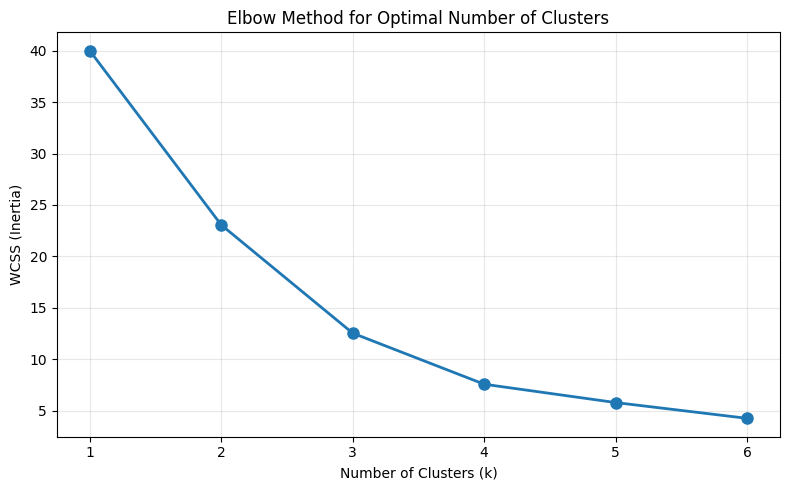

In [ ]:
# The Elbow Method helps determine a suitable number of clusters (k).
# It compares the Within-Cluster Sum of Squares (WCSS) for different k values.
# We look for the "elbow" where adding more clusters (k) stops reducing WCSS much.

# Compute WCSS for k=1 to k=6
k_values = range(1, 7)
wcss = []

# Create a K-Means model with the different number of clusters.
for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=50
    )

    model.fit(X_scaled)                        # The algorithm assigns customers to clusters and updates centroids iteratively until convergence.
    wcss.append(model.inertia_)                # Append the WCSS to the list for comparison across k values.

# Display WCSS for each k
print("Elbow Method Results:")
for k, value in zip(k_values, wcss):           # zip() pairs each k value with its corresponding WCSS.
    print(f"k={k}: WCSS = {value:.3f}")        # Print WCSS rounded to 3 decimal places.

# Plot the Elbow Method
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,            # X-axis: number of clusters (1 to 6)
    wcss,                # Y-axis: WCSS for each k
    color=COLORS[0],     # Use the first colour from the global COLORS list
    marker="o",          # Display a circular marker at each data point
    linewidth=2,         # Set the line thickness to 2 points
    markersize=8         # Set the marker size to 8 points
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Task 3: Sensitivity to initialisation

Seed 1: WCSS = 14.801
Seed 42: WCSS = 13.790
Seed 84: WCSS = 12.537

Cluster Assignments:
Customer  Seed_1  Seed_42  Seed_84
      C1       2        2        0
      C2       2        0        2
      C3       0        2        0
      C4       2        0        2
      C5       2        2        0
      C6       2        0        2
      C7       0        2        0
      C8       1        0        2
      C9       0        2        0
     C10       1        0        2
     C11       1        0        2
     C12       0        1        0
     C13       0        1        1
     C14       1        1        1
     C15       1        0        1
     C16       0        1        1
     C17       1        0        1
     C18       0        1        1
     C19       1        0        1
     C20       0        1        1


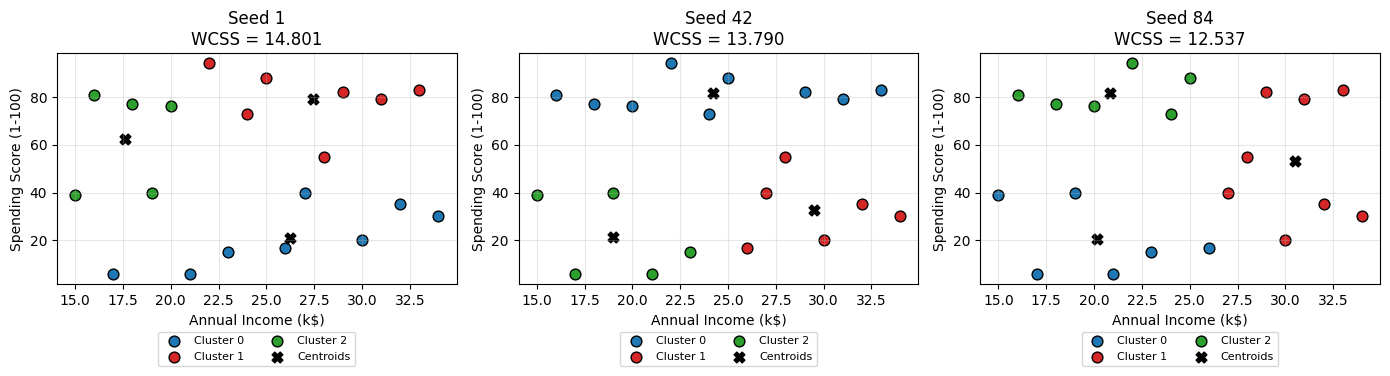

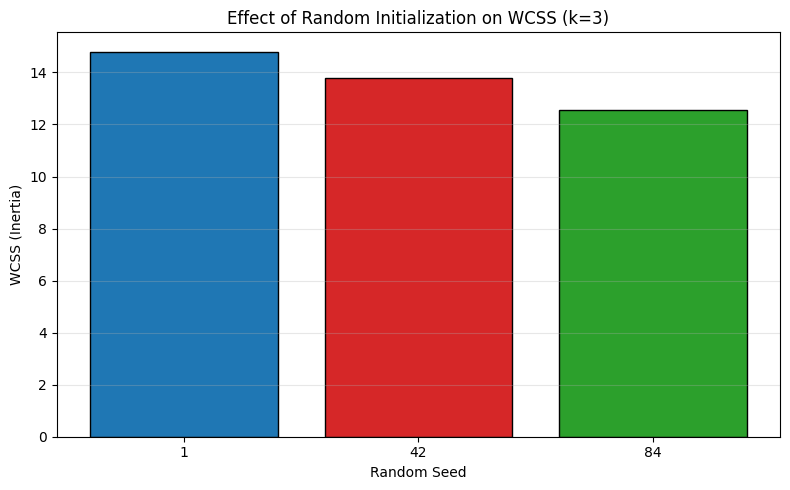

Lowest WCSS: 12.537
Highest WCSS: 14.801
WCSS Range: 2.263


In [ ]:
# Different initial centroids may lead to different cluster assignments and WCSS values, even when using the same dataset and k.
# We compare different random seeds while keeping k fixed.

# Run K-Means with different random seeds
seeds = [1, 42, 84]                                          # Define three random seeds to test.
k = 3                                                        # Fix the number of clusters at k=3 for a fair comparison.
results = {}                                                 # Create an empty dictionary to store each trained K-Means model.
assignments = pd.DataFrame({"Customer": df["Customer"]})     # Create a DataFrame to compare customer assignments across seeds.

# Create K-Means models with the same k but different seeds.
for seed in seeds:
    model = KMeans(
        n_clusters=k,         # Keep the number of clusters fixed at 3
        random_state=seed,    # Change the random seed for each run
        n_init=1              # Use only one initialization per seed
    )

    labels = model.fit_predict(X_scaled)                   # Train K-Means and obtain the cluster label for each customer.
    results[seed] = model                                  # Store the trained model in the dictionary using its seed as the key.
    assignments[f"Seed_{seed}"] = labels                   # Add the cluster assignments as a new column in the DataFrame.
    print(f"Seed {seed}: WCSS = {model.inertia_:.3f}")     # Display the WCSS for this particular seed.

print("\nCluster Assignments:")
print(assignments.to_string(index=False))


# Visualize clustering results for different seeds
# Create three subplots in one row, one for each random seed.
fig, axes = plt.subplots(1, len(seeds), figsize=(14, 4))

# Loop through each subplot and its corresponding seed.
for ax, seed in zip(axes, seeds):

    model = results[seed]       # Retrieve the trained K-Means model for the current seed.
    labels = model.labels_      # Retrieve the cluster labels assigned to each customer.

    for i in range(k):
        # Select customers belonging to the current cluster.
        cluster = df[labels == i]

        # Plot the selected customers using their original Income and Score.
        ax.scatter(
            cluster["Income"],
            cluster["Score"],
            color=COLORS[i],
            label=f"Cluster {i}",
            s=60,
            edgecolors="black"
        )

    # Convert centroids from standardized values to original units.
    centers = scaler.inverse_transform(model.cluster_centers_)

    # Plot the centroids.
    ax.scatter(
        centers[:, 0],
        centers[:, 1],
        color="black",
        marker="X",
        s=60,
        label="Centroids"
    )

    ax.set_title(f"Seed {seed}\nWCSS = {model.inertia_:.3f}")
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
    ax.grid(alpha=0.3)
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=2,
        frameon=True,
        fontsize=8
    )
plt.tight_layout()
plt.show()


# Compare WCSS across different random seeds
wcss_seeds = [results[seed].inertia_ for seed in seeds]   # Extract the WCSS from each stored K-Means model.
plt.figure(figsize=(8, 5))                                # Create a bar chart to compare WCSS across seeds.
plt.bar(
    [str(seed) for seed in seeds],   # Convert seeds to x-axis labels
    wcss_seeds,                      # WCSS for each seed
    color=COLORS[:len(seeds)],
    edgecolor="black"
)

# Add title, axis labels, and horizontal grid lines.
plt.title("Effect of Random Initialization on WCSS (k=3)")
plt.xlabel("Random Seed")
plt.ylabel("WCSS (Inertia)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Display the minimum, maximum, and range of WCSS values.
print(f"Lowest WCSS: {min(wcss_seeds):.3f}")
print(f"Highest WCSS: {max(wcss_seeds):.3f}")
print(f"WCSS Range: {max(wcss_seeds) - min(wcss_seeds):.3f}")


# Exercise 2: K-Means on two interlocking circles

K-Means Cluster Assignments:
 Point  Feature1  Feature2  TrueLabel  PredictedLabel
     1    0.1331   -0.5126          1               1
     2    0.4648   -0.1070          1               0
     3   -0.5205   -0.0741          1               1
     4    0.4625    0.3913          1               0
     5   -0.9720   -0.2337          0               1
     6   -0.8390   -0.5404          0               1
     7    0.3491   -0.4034          1               1
     8   -0.4556   -0.3020          1               1
     9    0.2823   -0.9513          0               1
    10    0.9885    0.0195          0               0
    11   -0.0522   -0.9507          0               1
    12   -0.4315    0.4549          1               0
    13    0.1283    0.5358          1               0
    14   -0.0563   -0.4657          1               1
    15    0.4846   -0.0224          1               0
    16   -0.1881   -0.9745          0               1
    17    0.3259    0.9493          0               0

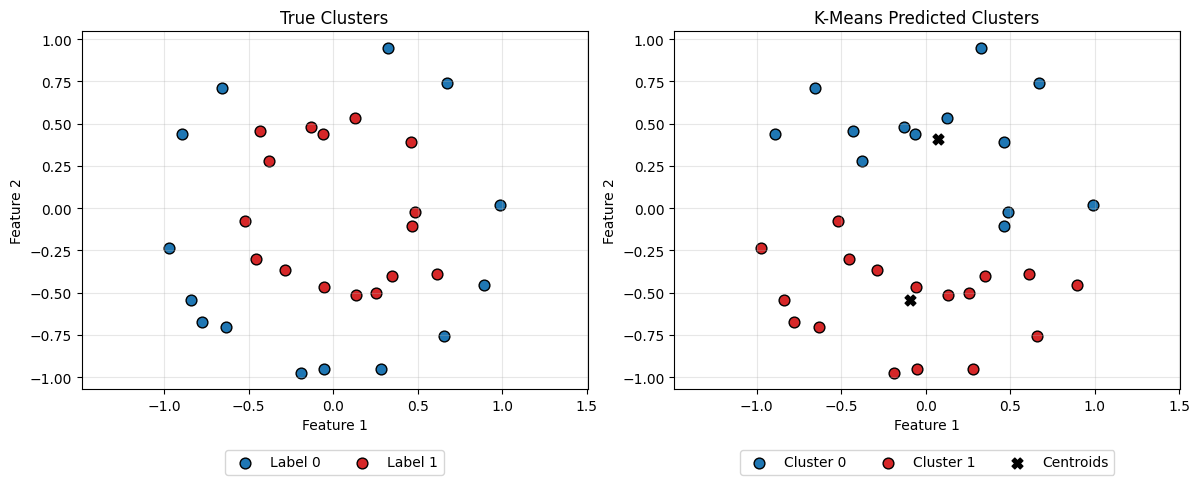

In [ ]:
# Define colours for the true labels
# True Label 0 = Blue; True Label 1 = Red
COLORS = ["tab:blue", "tab:red"]

# Step 1: Create the 30-point synthetic dataset
data = {
    "Point": list(range(1, 31)),
    "Feature1": [
        0.1331, 0.4648, -0.5205, 0.4625, -0.9720,
        -0.8390, 0.3491, -0.4556, 0.2823, 0.9885,
        -0.0522, -0.4315, 0.1283, -0.0563, 0.4846,
        -0.1881, 0.3259, -0.8930, -0.7778, 0.6570,
        -0.0618, 0.6709, -0.6336, -0.2857, -0.1296,
        0.2557, -0.6574, 0.8932, -0.3771, 0.6122
    ],
    "Feature2": [
        -0.5126, -0.1070, -0.0741, 0.3913, -0.2337,
        -0.5404, -0.4034, -0.3020, -0.9513, 0.0195,
        -0.9507, 0.4549, 0.5358, -0.4657, -0.0224,
        -0.9745, 0.9493, 0.4404, -0.6721, -0.7580,
        0.4373, 0.7405, -0.7034, -0.3625, 0.4794,
        -0.5007, 0.7107, -0.4518, 0.2763, -0.3904
    ],
    "TrueLabel": [
        1, 1, 1, 1, 0,
        0, 1, 1, 0, 0,
        0, 1, 1, 1, 1,
        0, 0, 0, 0, 0,
        1, 0, 0, 1, 1,
        1, 0, 0, 1, 1
    ]
}

df2 = pd.DataFrame(data)              # Convert the dictionary into a pandas DataFrame
X2 = df2[["Feature1", "Feature2"]]    # Extract the two numerical features for clustering


# Step 2: Apply K-Means with k=2
# Create a K-Means model with 2 clusters
kmeans2 = KMeans(n_clusters=2, random_state=42, n_init=50)

# fit_predict() fits the model, then store the predicted cluster labels
df2["PredictedLabel"] = kmeans2.fit_predict(X2)

# Retrieve the final centroid coordinates
centers2 = kmeans2.cluster_centers_

# Display the cluster assignments
print("K-Means Cluster Assignments:")
print(df2.to_string(index=False))

# Display WCSS and centroid coordinates
print(f"\nWCSS (Inertia): {kmeans2.inertia_:.3f}")
print("\nCluster Centroids:")

for i, center in enumerate(centers2):
    print(
        f"Cluster {i}: "
        f"({center[0]:.4f}, {center[1]:.4f})"
    )
print()


# Step 3: Visualize true clusters vs K-Means clusters with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Define the two sets of labels to compare
label_columns = ["TrueLabel", "PredictedLabel"]
titles = ["True Clusters", "K-Means Predicted Clusters"]

# Loop through both subplots
for ax, col, title in zip(axes, label_columns, titles):

    # Plot each cluster using its corresponding label
    for i in range(2):
        cluster = df2[df2[col] == i]

        ax.scatter(
            cluster["Feature1"],     # X-axis coordinates
            cluster["Feature2"],     # Y-axis coordinates
            color=COLORS[i],         # Label 0 = Blue, Label 1 = Red
            label=f"Label {i}" if col == "TrueLabel"
                  else f"Cluster {i}",
            s=60,
            edgecolors="black"
        )

    # Plot centroids on the K-Means subplot
    if col == "PredictedLabel":
        centers = kmeans2.cluster_centers_

        ax.scatter(
            centers[:, 0],
            centers[:, 1],
            color="black",
            marker="X",
            s=60,
            label="Centroids"
        )

    # Format each subplot
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.axis("equal")        # Use equal scaling on both axes to preserve the geometry
    ax.grid(alpha=0.3)

    # Position legend below each subplot
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=3,
        frameon=True
    )

plt.tight_layout()
plt.show()


# K-Means assumes compact, roughly spherical clusters and assigns points based on Euclidean distance to the nearest centroid.
# This produces straight-line decision boundaries (convex regions), which cannot separate the concentric circular clusters.
# As both circles share approximately the same centre, K-Means fails to capture their non-spherical structure, resulting in incorrect groupings.

# Exercise 3: Neural network classification (Bank Customer Subscription Prediction)

## 1. Problem Definition & Motivation

Project: Bank Customer Subscription Prediction (Binary classification)

Objective: Develop a feedforward neural network using PyTorch to predict whether a bank customer will subscribe to a term deposit based on customer demographics, financial information, and previous marketing interactions.

Real-world motivation: Banks can use predictive models to identify customers who are more likely to subscribe, potentially improving marketing efficiency and reducing unnecessary customer contacts.

Why a neural network: A feedforward neural network can learn nonlinear relationships between multiple customer attributes and subscription outcomes.

## 2.1 Install Package, Import Libraries, Load & Verify Dataset


The Bank Marketing dataset from the UCI Machine Learning Repository is selected for this project. It contains 45,211 records collected from direct marketing campaigns conducted by a Portuguese bank. The dataset includes 16 input features, such as customer age, occupation, account balance, loan status, and previous marketing interactions. The target variable, `y`, indicates whether a customer subscribed to a term deposit (`yes` or `no`), making this a binary classification problem.

In [ ]:
# Install the ucimlrepo package to download datasets directly from the UCI Machine Learning Repository.
%pip install -q ucimlrepo

import torch                  # PyTorch: building and training the neural network
import torch.nn as nn         # torch.nn: provides neural network layers and loss functions
import torch.optim as optim   # torch.optim: provides optimization algorithms

# DataLoader: divides datasets into mini-batches for training
# TensorDataset: combines input and target tensors into a dataset
from torch.utils.data import DataLoader, TensorDataset

# train_test_split: splits data into training, validation, and test sets
from sklearn.model_selection import train_test_split

# ColumnTransformer: applies different preprocessing to numerical and categorical features
from sklearn.compose import ColumnTransformer

# StandardScaler: standardizes numerical features
# OneHotEncoder: converts categorical features into numerical columns
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Evaluation metrics for classification
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

# deepcopy: creates an independent copy of the best model weights
from copy import deepcopy

# Set a fixed random seed to improve reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Import the function for downloading datasets from UCI
from ucimlrepo import fetch_ucirepo

# Download the Bank Marketing dataset using its UCI ID (222)
bank = fetch_ucirepo(id=222)

# Extract the input features (X) and target variable (y)
# .copy() creates independent DataFrames that we can modify safely
X_raw = bank.data.features.copy()
y_raw = bank.data.targets.copy()

# Combine the input features and target into one DataFrame
# axis=1 means joining the data side by side as columns
df = pd.concat([X_raw, y_raw], axis=1)

# Display the first five rows to understand the dataset structure
print("First 5 Rows:")
display(df.head())

# Display the number of rows and columns
print("Dataset Shape:", df.shape)

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

First 5 Rows:


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


Dataset Shape: (45211, 17)

Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day_of_week', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [ ]:
# These are the 16 features in the original bank-full.csv dataset
expected_features = [
    "age", "job", "marital", "education", "default",
    "balance", "housing", "loan", "contact", "day_of_week",
    "month", "duration", "campaign", "pdays",
    "previous", "poutcome"
]

# Check that the downloaded dataset contains these features
missing_features = [
    col for col in expected_features if col not in df.columns
]

if missing_features:
    raise ValueError(
        f"Expected Bank Marketing features not found: {missing_features}"
    )

# Keep the original 16 features and the target column
df = df[expected_features + ["y"]].copy()

# Display the target classes before converting them
print("Original Target Values:")
print(df["y"].value_counts(dropna=False))

# Convert the target from text into numeric labels
# "yes" -> 1: subscribed
# "no"  -> 0: did not subscribe
df["y"] = df["y"].map({"yes": 1, "no": 0})

# Check that every target was converted successfully
if df["y"].isna().any():
    raise ValueError("Unexpected or missing target values detected.")

# Convert target labels into integers
df["y"] = df["y"].astype(int)

# Display the numerical target distribution
print("\nEncoded Target Values:")
print(df["y"].value_counts())

# Display the number of customers and input features
print("\nNumber of Customers:", len(df))
print("Number of Input Features:", len(expected_features))

Original Target Values:
y
no     39922
yes     5289
Name: count, dtype: int64

Encoded Target Values:
y
0    39922
1     5289
Name: count, dtype: int64

Number of Customers: 45211
Number of Input Features: 16


## 2.2 Exploratory Data Analysis (EDA)

Dataset Shape: (45211, 17)

First 5 Rows:


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no



Data Types:
age             int64
job            object
marital        object
education      object
default        object
balance         int64
housing        object
loan           object
contact        object
day_of_week     int64
month          object
duration        int64
campaign        int64
pdays           int64
previous        int64
poutcome       object
y              object
dtype: object

Missing Values:
age                0
job              288
marital            0
education       1857
default            0
balance            0
housing            0
loan               0
contact        13020
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       36959
y                  0
dtype: int64

Numerical Summary Statistics:


,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000



Categorical Summary Statistics:


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,44923,45211,43354,45211,45211,45211,32191,45211,8252,45211
unique,11,3,3,2,2,2,2,12,3,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,failure,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,4901,39922



Subscription Distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Subscription Percentage:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64

Correlation Matrix:


,age,balance,day_of_week,duration,campaign,pdays,previous,y
age,1.00,0.10,-0.01,-0.00,0.00,-0.02,0.00,0.03
balance,0.10,1.00,0.00,0.02,-0.01,0.00,0.02,0.05
day_of_week,-0.01,0.00,1.00,-0.03,0.16,-0.09,-0.05,-0.03
duration,-0.00,0.02,-0.03,1.00,-0.08,-0.00,0.00,0.39
campaign,0.00,-0.01,0.16,-0.08,1.00,-0.09,-0.03,-0.07
pdays,-0.02,0.00,-0.09,-0.00,-0.09,1.00,0.45,0.10
previous,0.00,0.02,-0.05,0.00,-0.03,0.45,1.00,0.09
y,0.03,0.05,-0.03,0.39,-0.07,0.10,0.09,1.00



Correlation with Subscription:
duration       0.395
pdays          0.104
previous       0.093
balance        0.053
age            0.025
day_of_week   -0.028
campaign      -0.073
Name: y, dtype: float64


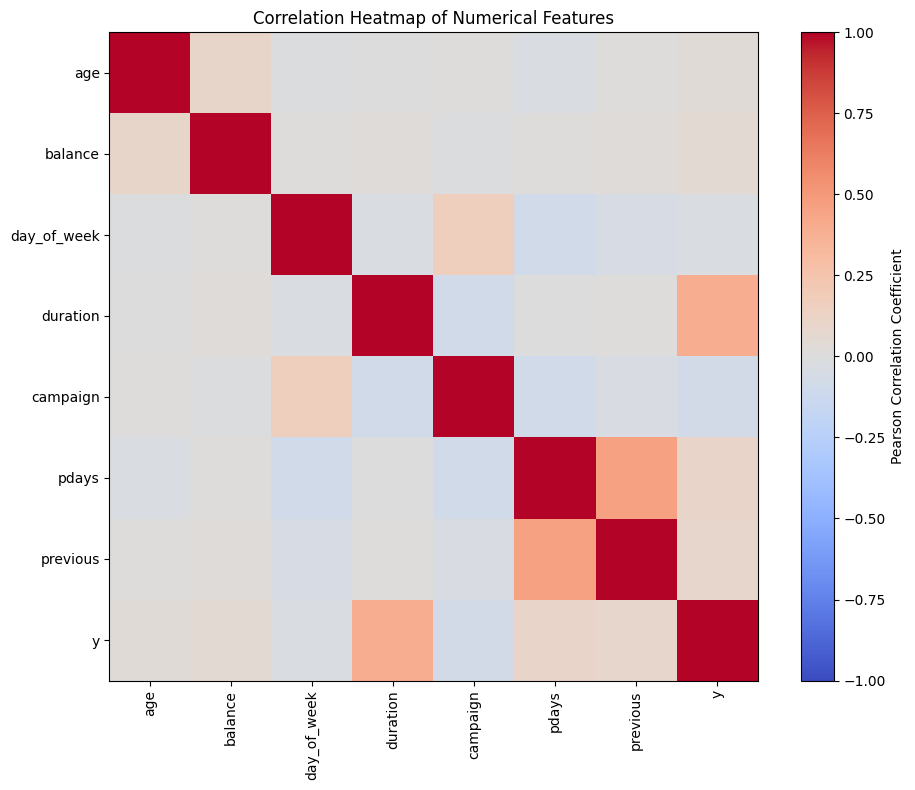

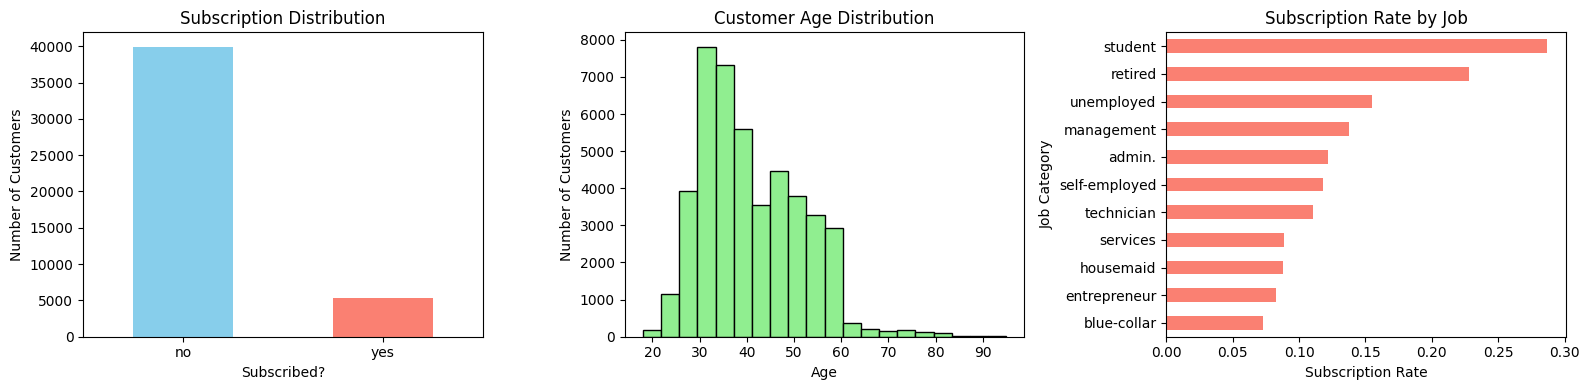

In [ ]:
# ============================================================
# PART 3: EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

# Use the original dataset to avoid accidentally modifying
# the target variable during exploratory analysis.
df = pd.concat([X_raw, y_raw], axis=1).copy()


# ------------------------------------------------------------
# 1. SUMMARY STATISTICS
# ------------------------------------------------------------

# Display the number of rows (customers) and columns (variables).
print("Dataset Shape:", df.shape)

# Display the first 5 rows to understand the dataset structure.
print("\nFirst 5 Rows:")
display(df.head())

# Check the data type of each variable.
# Numerical variables: e.g. age, balance, campaign.
# Categorical variables: e.g. job, marital, education.
print("\nData Types:")
print(df.dtypes)

# Check for missing values in each column.
# Missing values may need to be handled before model training.
print("\nMissing Values:")
print(df.isnull().sum())

# Display summary statistics for numerical variables.
# Includes count, mean, standard deviation, minimum,
# maximum, and quartiles (25%, 50%, 75%).
print("\nNumerical Summary Statistics:")
display(df.describe())

# Display summary statistics for categorical variables.
# Includes number of unique categories and most frequent values.
print("\nCategorical Summary Statistics:")
display(df.describe(include="object"))

# Check how many customers subscribed (yes) or did not (no).
# This helps identify whether the target classes are imbalanced.
print("\nSubscription Distribution:")
print(df["y"].value_counts())

# Calculate the percentage of customers in each class.
print("\nSubscription Percentage:")
print((df["y"].value_counts(normalize=True) * 100).round(2))


# ------------------------------------------------------------
# 2. CORRELATION ANALYSIS
# ------------------------------------------------------------

# Correlation measures the strength and direction of a
# linear relationship between two numerical variables.
# Values range from -1 (negative) to +1 (positive).
# A value near 0 indicates weak linear correlation.

# Select numerical columns for correlation analysis.
df_corr = df.select_dtypes(include="number").copy()

# Convert the target variable into numerical values:
# yes = 1 (subscribed), no = 0 (did not subscribe).
# This allows us to include the target in the correlation matrix.
df_corr["y"] = df["y"].map({"yes": 1, "no": 0})

# Calculate Pearson correlation coefficients.
corr = df_corr.corr()

# Display the correlation matrix.
print("\nCorrelation Matrix:")
display(corr.round(2))

# Display correlations between numerical features and subscription.
# This helps identify which numerical variables have stronger
# positive or negative linear relationships with the target.
print("\nCorrelation with Subscription:")
print(corr["y"].drop("y").sort_values(ascending=False).round(3))

# Plot the correlation matrix as a heatmap.
plt.figure(figsize=(10, 8))

plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson Correlation Coefficient")

# Label the rows and columns with feature names.
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. DATA VISUALIZATIONS
# ------------------------------------------------------------

# Create three plots side by side to explore:
# (1) Subscription distribution
# (2) Customer age distribution
# (3) Subscription rate by occupation

fig, axes = plt.subplots(1, 3, figsize=(16, 4))


# Plot 1: Subscription Distribution
# A bar chart shows how many customers subscribed or did not.
# This helps us identify class imbalance.

df["y"].value_counts().reindex(["no", "yes"]).plot(
    kind="bar",
    ax=axes[0],
    color=["skyblue", "salmon"]
)

axes[0].set_title("Subscription Distribution")
axes[0].set_xlabel("Subscribed?")
axes[0].set_ylabel("Number of Customers")
axes[0].tick_params(axis="x", rotation=0)


# Plot 2: Customer Age Distribution
# A histogram shows how customer ages are distributed.
# Each bar represents the number of customers in an age range.

axes[1].hist(
    df["age"],
    bins=20,
    color="lightgreen",
    edgecolor="black"
)

axes[1].set_title("Customer Age Distribution")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Number of Customers")


# Plot 3: Subscription Rate by Job
# First, convert subscription outcomes to numerical values.
# The average of 0s and 1s gives the subscription rate.
# For example, a mean of 0.15 means 15% subscribed.

df_job = df.copy()
df_job["subscribed"] = df_job["y"].map({"yes": 1, "no": 0})

# Calculate the average subscription rate for each job category.
job_rates = df_job.groupby("job")["subscribed"].mean()

# Sort the rates from lowest to highest for easier comparison.
job_rates.sort_values().plot(
    kind="barh",
    ax=axes[2],
    color="salmon"
)

axes[2].set_title("Subscription Rate by Job")
axes[2].set_xlabel("Subscription Rate")
axes[2].set_ylabel("Job Category")

# Adjust spacing so labels do not overlap.
plt.tight_layout()
plt.show()


## 2.3 Data Preprocessing

In [ ]:
# 1. Separate input features (X) and target variable (y)

# Remove 'duration' because call duration is only known after the call.
X = df.drop(columns=["y", "duration"])

# Convert the target into numerical labels:
# yes = 1 (subscribed), no = 0 (did not subscribe)
y = df["y"].map({"yes": 1, "no": 0})

print("Number of Input Features:", X.shape[1])


# 2. Split the dataset into 60% training, 20% validation, 20% testing

# First split: 60% training, 40% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

# Second split: divide the remaining 40% equally
# into 20% validation and 20% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

print("\nTraining Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))


# 3. Identify numerical and categorical features

# Numerical features include age, balance, campaign, etc.
num_cols = X.select_dtypes(include="number").columns.tolist()

# Categorical features include job, education, housing, etc.
cat_cols = X.select_dtypes(exclude="number").columns.tolist()


# 4. Standardize numerical features and encode categorical features

# StandardScaler: scales numerical features to mean 0 and std 1.
# OneHotEncoder: converts categories into binary columns (0 or 1).
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore",
                          sparse_output=False), cat_cols)
])

# Fit the preprocessor using ONLY training data to prevent data leakage.
X_train = preprocessor.fit_transform(X_train)

# Apply the same transformations to validation and test data.
X_val = preprocessor.transform(X_val)
X_test = preprocessor.transform(X_test)

print("\nProcessed Training Shape:", X_train.shape)
print("Processed Validation Shape:", X_val.shape)
print("Processed Testing Shape:", X_test.shape)

Number of Input Features: 15

Training Samples: 27126
Validation Samples: 9042
Testing Samples: 9043

Processed Training Shape: (27126, 50)
Processed Validation Shape: (9042, 50)
Processed Testing Shape: (9043, 50)


## 3.1 Convert Data into PyTorch Tensors and Data Loaders

In [ ]:
# 1. Convert the processed data into PyTorch tensors
# float32 is commonly used for neural network calculations.

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

# Convert the target labels into tensors.
# reshape(-1, 1) gives each label a shape of [1],
# matching the neural network's single output neuron.
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32).reshape(-1, 1)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.float32).reshape(-1, 1)
y_test_tensor = torch.tensor(y_test.to_numpy(), dtype=torch.float32).reshape(-1, 1)


# 2. Combine input features and labels into datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)


# 3. Create DataLoaders
# batch_size=64 means the model processes 64 customers at a time.
# shuffle=True randomizes training samples each epoch.
# Validation and test data do not need shuffling.

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)


# 4. Verify the tensor shapes
print("Training Input Shape:", X_train_tensor.shape)
print("Training Target Shape:", y_train_tensor.shape)
print("Number of Training Batches:", len(train_loader))

Training Input Shape: torch.Size([27126, 50])
Training Target Shape: torch.Size([27126, 1])
Number of Training Batches: 424


## 3.2 Feedforward Neural Network Architecture

BankNN(
  (network): Sequential(
    (0): Linear(in_features=50, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


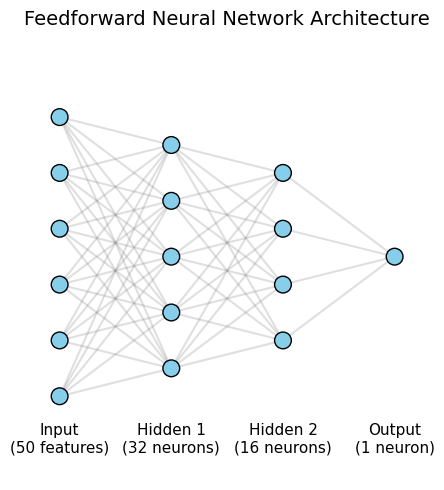

In [ ]:
import torch.nn as nn

# Define a simple feedforward neural network
class BankNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        # Define the layers of the neural network
        self.network = nn.Sequential(
            nn.Linear(input_size, 32),  # Input layer -> 32 neurons
            nn.ReLU(),                  # ReLU activation function

            nn.Linear(32, 16),          # 32 -> 16 neurons
            nn.ReLU(),                  # ReLU activation function

            nn.Linear(16, 1)            # Output: one value (logit)
        )

    # Define how input data passes through the network
    def forward(self, x):
        return self.network(x)


# Number of input features after preprocessing
input_size = X_train.shape[1]

# Create an instance of the neural network
model = BankNN(input_size)

# Display the neural network architecture
print(model)

# Visualize the neural network architecture
# Define the number of neurons in each layer
# Show up to 6 input neurons to keep the diagram readable
layers = [min(input_size, 6), 5, 4, 1]
labels = [f"Input\n({input_size} features)",
          "Hidden 1\n(32 neurons)",
          "Hidden 2\n(16 neurons)",
          "Output\n(1 neuron)"]

fig, ax = plt.subplots(figsize=(10, 5))

# Store neuron positions for connecting layers
positions = []

for i, n in enumerate(layers):
    x = i * 2
    y_positions = [j - (n - 1) / 2 for j in range(n)]
    positions.append([(x, y) for y in y_positions])

    # Draw neurons as circles
    for y in y_positions:
        ax.add_patch(plt.Circle((x, y), 0.15, color="skyblue", ec="black"))

    # Add layer labels
    ax.text(x, -3.5, labels[i], ha="center", fontsize=11)

# Connect neurons between consecutive layers
for i in range(len(positions) - 1):
    for x1, y1 in positions[i]:
        for x2, y2 in positions[i + 1]:
            ax.plot([x1, x2], [y1, y2], color="gray", alpha=0.25, zorder=0)

ax.set_xlim(-0.5, 6.5)
ax.set_ylim(-4, 4)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Feedforward Neural Network Architecture", fontsize=14)

plt.tight_layout()
plt.savefig("bank_neural_network.png", dpi=300, bbox_inches="tight")
plt.show()


## 4. Neural Network Training

In [ ]:
# Binary Cross-Entropy Loss for binary classification.
# BCEWithLogitsLoss automatically applies sigmoid internally.
criterion = nn.BCEWithLogitsLoss()

# Adam optimizer updates the model's weights during training.
# Learning rate controls how large each weight update is.
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Number of times the model goes through the training dataset
epochs = 100

# Store losses for plotting later
train_losses = []
val_losses = []
test_losses = []

for epoch in range(epochs):

    # 1. Training phase
    model.train()  # Set the model to training mode
    total_train_loss = 0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()       # Clear gradients from previous batch
        outputs = model(X_batch)    # Forward pass: make predictions
        loss = criterion(outputs, y_batch)  # Calculate prediction error
        loss.backward()             # Backpropagation: calculate gradients
        optimizer.step()            # Update model weights

        # Multiply by batch size to calculate average loss per sample
        total_train_loss += loss.item() * len(X_batch)

    # Average training loss across all samples
    train_loss = total_train_loss / len(train_dataset)
    train_losses.append(train_loss)

    # 2. Validation phase
    model.eval()  # Set the model to evaluation mode
    total_val_loss = 0

    # Disable gradient calculations because we are not training
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            total_val_loss += loss.item() * len(X_batch)

    # Average validation loss across all samples
    val_loss = total_val_loss / len(val_dataset)
    val_losses.append(val_loss)

    # 3. Test phase
    model.eval()
    total_test_loss = 0

    # Disable gradient calculations during testing
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            total_test_loss += loss.item() * len(X_batch)

    # Average test loss across all samples
    test_loss = total_test_loss / len(test_dataset)
    test_losses.append(test_loss)

    # Print progress every 10 epochs
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {train_loss:.4f}, "
            f"Val Loss: {val_loss:.4f}, "
            f"Test Loss: {test_loss:.4f}"
        )

Epoch [10/100] Train Loss: 0.2872, Val Loss: 0.2914, Test Loss: 0.2835
Epoch [20/100] Train Loss: 0.2788, Val Loss: 0.2905, Test Loss: 0.2844
Epoch [30/100] Train Loss: 0.2736, Val Loss: 0.2924, Test Loss: 0.2872
Epoch [40/100] Train Loss: 0.2688, Val Loss: 0.2946, Test Loss: 0.2892
Epoch [50/100] Train Loss: 0.2654, Val Loss: 0.2969, Test Loss: 0.2928
Epoch [60/100] Train Loss: 0.2618, Val Loss: 0.3009, Test Loss: 0.2942
Epoch [70/100] Train Loss: 0.2580, Val Loss: 0.3023, Test Loss: 0.2979
Epoch [80/100] Train Loss: 0.2558, Val Loss: 0.3076, Test Loss: 0.3016
Epoch [90/100] Train Loss: 0.2544, Val Loss: 0.3136, Test Loss: 0.3062
Epoch [100/100] Train Loss: 0.2521, Val Loss: 0.3125, Test Loss: 0.3081


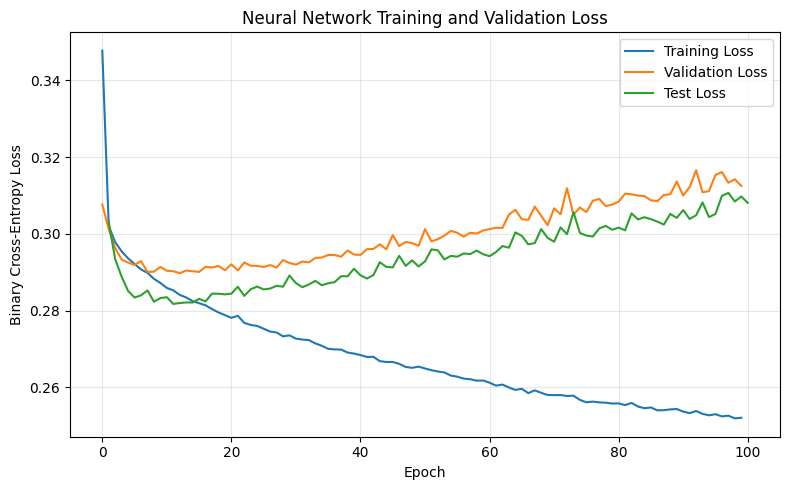

In [ ]:
plt.figure(figsize=(8, 5))

# Plot the training and validation losses across epochs
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.plot(range(1, epochs + 1), test_losses, label="Test Loss")

plt.title("Neural Network Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 5. Model Evaluation

### 5.1 Evaluate Training, Validation and Test Sets Performance

In [ ]:
# Function to evaluate the model on any dataset
def evaluate_model(data_loader):

    model.eval()  # Set model to evaluation mode

    all_preds = []
    all_labels = []
    total_loss = 0

    # Disable gradient calculations during evaluation
    with torch.no_grad():
        for X_batch, y_batch in data_loader:

            # Get raw predictions (logits)
            outputs = model(X_batch)

            # Calculate binary cross-entropy loss
            loss = criterion(outputs, y_batch)

            # Convert logits into probabilities (0 to 1)
            probabilities = torch.sigmoid(outputs)

            # Convert probabilities into binary predictions
            predictions = (probabilities >= 0.5).int()

            # Store predictions and actual labels
            all_preds.extend(predictions.numpy().flatten())
            all_labels.extend(y_batch.numpy().flatten())

            # Accumulate loss
            total_loss += loss.item() * len(X_batch)

    # Calculate average loss
    avg_loss = total_loss / len(data_loader.dataset)

    # Return evaluation metrics
    return {
        "Loss": avg_loss,
        "Accuracy": accuracy_score(all_labels, all_preds),
        "Precision": precision_score(all_labels, all_preds, zero_division=0),
        "Recall": recall_score(all_labels, all_preds, zero_division=0)
    }


# Evaluate all three datasets
train_results = evaluate_model(train_loader)
val_results = evaluate_model(val_loader)
test_results = evaluate_model(test_loader)

# Display results in a table
results_df = pd.DataFrame(
    [train_results, val_results, test_results],
    index=["Training", "Validation", "Test"]
)

print("Model Performance:")
display(results_df.round(4))

Model Performance:


,Loss,Accuracy,Precision,Recall
Training,0.2472,0.9122,0.7351,0.3892
Validation,0.3125,0.8921,0.5792,0.2836
Test,0.3081,0.8903,0.5598,0.2921


### 5.2 Plot the Confusion Matrix

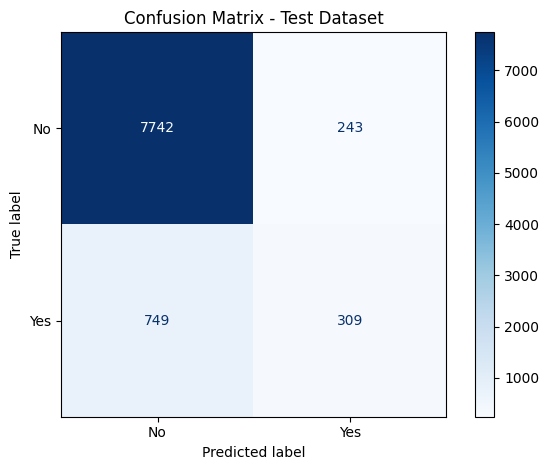

                 precision    recall  f1-score   support

No Subscription       0.91      0.97      0.94      7985
   Subscription       0.56      0.29      0.38      1058

       accuracy                           0.89      9043
      macro avg       0.74      0.63      0.66      9043
   weighted avg       0.87      0.89      0.87      9043



In [ ]:
# Generate predictions for the test dataset
model.eval()

with torch.no_grad():

    # Predict probabilities for all test customers
    outputs = model(X_test_tensor)
    probabilities = torch.sigmoid(outputs)

    # Convert probabilities into binary predictions
    y_pred = (probabilities >= 0.5).int().numpy().flatten()

# Plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Test Dataset")
plt.tight_layout()
plt.show()

# Display precision, recall and F1-score for both classes
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Subscription", "Subscription"],
    zero_division=0
))


## 6. Overfitting Analysis

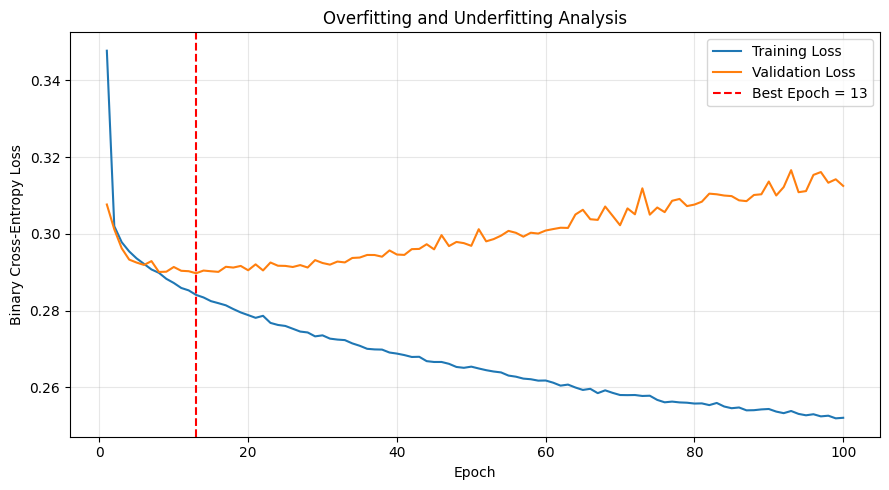

Best Epoch: 13
Lowest Validation Loss: 0.2897
Final Training Loss: 0.2521
Final Validation Loss: 0.3125


,Loss,Accuracy,Precision,Recall
Training,0.2472,0.9122,0.7351,0.3892
Validation,0.3125,0.8921,0.5792,0.2836
Test,0.3081,0.8903,0.5598,0.2921


Training-Validation Loss Gap: 0.0604


In [ ]:
# Find the epoch with the lowest validation loss
best_epoch = np.argmin(val_losses) + 1

plt.figure(figsize=(9, 5))

plt.plot(range(1, epochs + 1), train_losses, label="Training Loss")
plt.plot(range(1, epochs + 1), val_losses, label="Validation Loss")

# Highlight the epoch with the best validation performance
plt.axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch = {best_epoch}"
)

plt.title("Overfitting and Underfitting Analysis")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Best Epoch: {best_epoch}")
print(f"Lowest Validation Loss: {min(val_losses):.4f}")
print(f"Final Training Loss: {train_losses[-1]:.4f}")
print(f"Final Validation Loss: {val_losses[-1]:.4f}")

# Compare accuracy, loss, precision and recall across datasets
display(results_df[["Loss", "Accuracy", "Precision", "Recall"]].round(4))

# Calculate the difference between training and validation loss
loss_gap = val_losses[-1] - train_losses[-1]

print(f"Training-Validation Loss Gap: {loss_gap:.4f}")

## 7. Learning Rate Ablation Study

### 7.1 Train Models with Different Learning Rate

In [ ]:
learning_rates = [0.1, 0.01, 0.001]

# Store training and validation losses for each learning rate
lr_results = {}

# Save the initial model weights for a fair comparison
torch.manual_seed(42)
initial_weights = deepcopy(BankNN(input_size).state_dict())

for lr in learning_rates:

    # Create a new model with the same architecture
    lr_model = BankNN(input_size)

    # Start each experiment from the same initial weights
    lr_model.load_state_dict(initial_weights)

    # Define loss function and optimizer
    lr_criterion = nn.BCEWithLogitsLoss()
    lr_optimizer = torch.optim.Adam(lr_model.parameters(), lr=lr)

    train_history = []
    val_history = []

    for epoch in range(100):

        # Training phase
        lr_model.train()
        train_loss = 0

        for X_batch, y_batch in train_loader:
            lr_optimizer.zero_grad()

            outputs = lr_model(X_batch)
            loss = lr_criterion(outputs, y_batch)

            loss.backward()
            lr_optimizer.step()

            train_loss += loss.item() * len(X_batch)

        train_history.append(train_loss / len(train_dataset))

        # Validation phase
        lr_model.eval()
        val_loss = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                outputs = lr_model(X_batch)
                loss = lr_criterion(outputs, y_batch)
                val_loss += loss.item() * len(X_batch)

        val_history.append(val_loss / len(val_dataset))

    # Store results
    lr_results[lr] = {
        "train_loss": train_history,
        "val_loss": val_history
    }

    print(f"Learning Rate: {lr} | Final Validation Loss: {val_history[-1]:.4f}")

Learning Rate: 0.1 | Final Validation Loss: 0.3610
Learning Rate: 0.01 | Final Validation Loss: 0.3600
Learning Rate: 0.001 | Final Validation Loss: 0.3153


### 7.2 Plot the Learning Rate Comparison

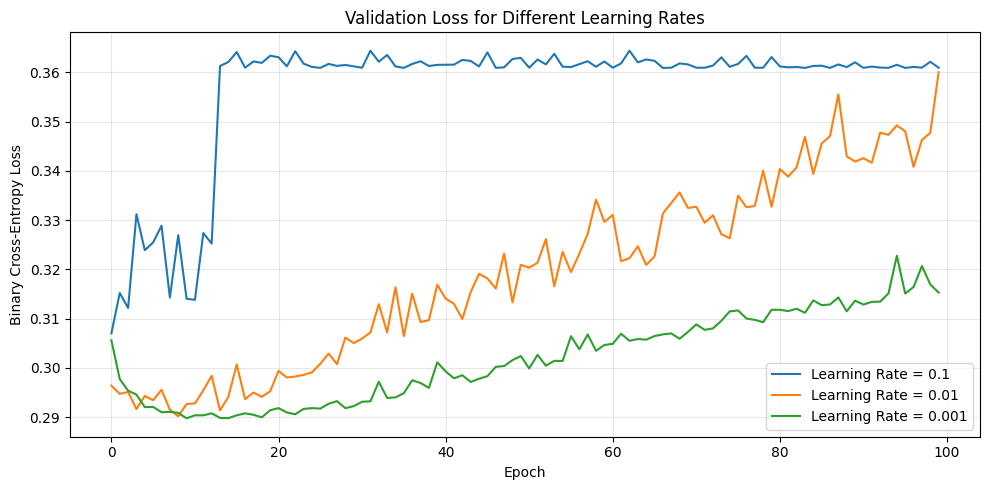

In [ ]:
plt.figure(figsize=(10, 5))

for lr in learning_rates:
    plt.plot(
        lr_results[lr]["val_loss"],
        label=f"Learning Rate = {lr}"
    )

plt.title("Validation Loss for Different Learning Rates")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 7.3 Compare the Results

In [ ]:
comparison = []

for lr in learning_rates:
    comparison.append({
        "Learning Rate": lr,
        "Final Training Loss": lr_results[lr]["train_loss"][-1],
        "Final Validation Loss": lr_results[lr]["val_loss"][-1],
        "Best Validation Loss": min(lr_results[lr]["val_loss"])
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Learning Rate,Final Training Loss,Final Validation Loss,Best Validation Loss
0,0.100,0.3618,0.3610,0.3070
1,0.010,0.2486,0.3600,0.2902
2,0.001,0.2499,0.3153,0.2897


## 8. Case Study: Successes and Failures

The model successfully classified most non-subscribers, correctly identifying 7,742 out of 7,985 customers. However, it only correctly identified 309 out of 1,058 subscribers, missing 749 actual subscribers. This indicates that the model performs well in predicting non-subscriptions but struggles to identify potential subscribers. The high number of false negatives may be attributed to class imbalance, as the model tends to favour the majority class. Future improvements could include class weighting or resampling techniques to improve the detection of subscribers.

## 9. Discussion & Future Work

This project developed a feedforward neural network using PyTorch to predict whether bank customers would subscribe to a term deposit.

The model was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. Training and validation losses were compared to investigate overfitting and underfitting, while a learning rate ablation study examined the effects of different learning rates.

**Limitations:** The dataset contains imbalanced classes, which may affect the model's ability to identify customers who subscribe. The model's performance may also depend on the selected architecture and hyperparameters.

**Future Improvements:** Potential improvements include early stopping, dropout, class weighting, hyperparameter tuning, and comparison with other machine learning models.

Overall, this project demonstrates the application of neural networks to a real-world binary classification problem in bank marketing.